# Notebook 2 of 2 — Pretrained GridSFM DERATE predictions + line-level SHAP

**Run Notebook 1 first:** `01_gaussian_derate_sampling_acopf.ipynb`.

This notebook **never calls Julia**. It loads the saved derated candidate grids, uses only the pretrained GridSFM **feasibility head** for feasible/infeasible predictions, and explains **which specific derated lines** influenced the prediction. Lines are identified by their **original branch IDs** and their **from/to buses**.

- First select an individual candidate by predicted class and confidence (optional dropdown; manual index fallback).
- Apply **group Kernel SHAP** to all changed branches in that candidate. Each branch's three rating changes (`rate_a/b/c`) are toggled *together*, preserving the physical derating mechanism.
- Apply more detailed **conditional line-level Kernel SHAP** to selected branches, with all other candidate branches held at their derated values.
- Save model predictions and per-line attributions to CSV and charts.

The `.pyg.json` schema has `ac_line.edge_attr[:,6:9] = [rate_a,rate_b,rate_c]`. Branch-ID matching uses `metadata.ac_line_branch_ids`, not an assumed row order; fail with a clear error if data mappings do not align. 

**SHAP shows how inputs affect the pretrained model's prediction; it does not prove which line physically caused AC-OPF infeasibility.**

## 1. Dataset, sampling archive and output directory

In [1]:
import csv
import hashlib
import json
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

DATASET_NAME="alabama"      # Must match Notebook 1
TIME_SLICE="16h"
SCENARIO_PATH_OVERRIDE=None # Path("/absolute/path/to/acopf_labeled_scenarios.npz")
DATASET_LABEL=DATASET_NAME.replace("_"," ").title()

def find_project_root():
    current=Path.cwd().resolve()
    for parent in (current,*current.parents):
        for candidate in (parent,parent/"GridSFM"):
            if (candidate/"model").is_dir() and (candidate/"verifier").is_dir():
                return candidate.resolve()
    raise FileNotFoundError("Run in GridSFM, which must contain model/ and verifier/")

PROJECT_ROOT=find_project_root()
MODEL_DIR=PROJECT_ROOT/"model"
GRID_DATA_ROOT=next((p for p in (PROJECT_ROOT/"power_grid",PROJECT_ROOT.parent/"power_grid")
                     if (p/"US"/"gridsfm_data").is_dir()),None)
if GRID_DATA_ROOT is None: raise FileNotFoundError("Missing power_grid/US/gridsfm_data")
DATA_DIR=GRID_DATA_ROOT/"US"/"gridsfm_data"/TIME_SLICE
DATA_PATH=DATA_DIR/f"{DATASET_NAME}_model.json"
SCENARIO_PATH=(Path(SCENARIO_PATH_OVERRIDE).expanduser().resolve()
               if SCENARIO_PATH_OVERRIDE is not None else
               PROJECT_ROOT/"results"/"gaussian_line_derate"/DATASET_NAME/"acopf_labeled_scenarios.npz")
assert DATA_PATH.is_file(),DATA_PATH
assert SCENARIO_PATH.is_file(),f"Run derate Notebook 1 first: {SCENARIO_PATH}"
with DATA_PATH.open("r",encoding="utf-8") as f: data=json.load(f)
CASE_SHA256=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
EXPLAIN_ROOT=SCENARIO_PATH.parent/"gridsfm_pretrained_derate_line_shap"
EXPLAIN_ROOT.mkdir(parents=True,exist_ok=True)
print("Grid:",DATA_PATH,"| candidate archive:",SCENARIO_PATH)
print("SHAP output:",EXPLAIN_ROOT)

Grid: /Users/punrong_rany/Desktop/Projects/GridSFM/power_grid/US/gridsfm_data/16h/alabama_model.json | candidate archive: /Users/punrong_rany/Desktop/Projects/GridSFM/results/gaussian_line_derate/alabama/acopf_labeled_scenarios.npz
SHAP output: /Users/punrong_rany/Desktop/Projects/GridSFM/results/gaussian_line_derate/alabama/gridsfm_pretrained_derate_line_shap


## 2. Load pretrained GridSFM model and original raw PyG graph

Edit the optional override paths if your checkpoint or PyG file lives elsewhere. Use the **unprepared** PyG graph so the rating features can be replaced before `prepare_for_inference`.

In [2]:
if str(MODEL_DIR) not in sys.path: sys.path.insert(0,str(MODEL_DIR))
import torch
from captum.attr import KernelShap
from gridsfm import load_model,load_pyg_json,prepare_for_inference

DEVICE=torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
CHECKPOINT_PATH_OVERRIDE=None
PYG_PATH_OVERRIDE=None
CHECKPOINT_CANDIDATES=[MODEL_DIR/"checkpoints"/"gridsfm_open_v1.1.pt"]
PYG_CANDIDATES=[
    DATA_DIR/f"{DATASET_NAME}_model.pyg.json",
    GRID_DATA_ROOT/"US"/"topology_solver_pipeline"/"output"/
        f"{DATASET_NAME}_{TIME_SLICE}"/f"{DATASET_NAME}_model.pyg.json",
    MODEL_DIR/"samples"/f"msr_{DATASET_NAME}.pyg.json",
]
def first_existing(options,label):
    match=next((p.resolve() for p in options if p.is_file()),None)
    if match is None:
        raise FileNotFoundError(f"Missing {label}; checked {[str(p) for p in options]}. Set *_PATH_OVERRIDE.")
    return match
CHECKPOINT_PATH=first_existing([Path(CHECKPOINT_PATH_OVERRIDE)] if CHECKPOINT_PATH_OVERRIDE
                               else CHECKPOINT_CANDIDATES,"pretrained checkpoint")
PYG_PATH=first_existing([Path(PYG_PATH_OVERRIDE)] if PYG_PATH_OVERRIDE else PYG_CANDIDATES,"PyG graph")
grid_model=load_model(str(CHECKPOINT_PATH),device=str(DEVICE))
grid_model.eval()
for p in grid_model.parameters(): p.requires_grad_(False)
raw_graph=load_pyg_json(PYG_PATH)
with PYG_PATH.open("r",encoding="utf-8") as f:
    pyg_metadata=json.load(f).get("metadata",{})
EDGE_TYPE=("bus","ac_line","bus")
if EDGE_TYPE not in raw_graph.edge_types:
    raise ValueError("Selected PyG graph contains no ac_line edges; cannot explain line derating")
raw_edge_attr=raw_graph[EDGE_TYPE].edge_attr
if raw_edge_attr.ndim!=2 or raw_edge_attr.shape[1]<9:
    raise ValueError("Expected raw ac_line edge features [angmin,angmax,b_fr,b_to,r,x,rate_a,rate_b,rate_c]")
print("Pretrained checkpoint:",CHECKPOINT_PATH,"| device:",DEVICE)
print("Raw PyG:",PYG_PATH,"| AC lines:",len(raw_edge_attr))

/Users/punrong_rany/Desktop/Projects/GridSFM/model/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Pretrained checkpoint: /Users/punrong_rany/Desktop/Projects/GridSFM/model/checkpoints/gridsfm_open_v1.1.pt | device: cpu
Raw PyG: /Users/punrong_rany/Desktop/Projects/GridSFM/power_grid/US/topology_solver_pipeline/output/alabama_16h/alabama_model.pyg.json | AC lines: 590


## 3. Validate the branch-ID ↔ PyG-edge mapping and original ratings

The official exporter records `metadata.ac_line_branch_ids`. This is required to map SHAP scores to physical branches. The check also ensures every sampled branch exists in the PyG graph with the same starting `rate_a/b/c` values.

In [3]:
with np.load(SCENARIO_PATH,allow_pickle=False) as saved:
    candidates=saved["candidates"].astype(np.float32)
    saved_branch_ids=saved["branch_ids"].astype(str)
    saved_branch_rates=saved["branch_rates"].astype(np.float32)
    selected_branch_ids=saved["selected_branch_ids"].astype(str)
    saved_factors=saved["derate_factors"].astype(np.float32)
    saved_iteration=saved["iteration"].astype(int)
    saved_scenario=saved["scenario"].astype(int)
    saved_name=str(saved["dataset_name"].item())
    saved_sha=str(saved["source_case_sha256"].item())
assert saved_name==DATASET_NAME,f"Archive is for {saved_name}, not {DATASET_NAME}"
assert saved_sha==CASE_SHA256,"Source grid differs from the case used for sampling"
assert candidates.ndim==3 and candidates.shape[1:]==saved_branch_rates.shape
assert candidates.shape[2]==3 and len(candidates)==len(selected_branch_ids)==len(saved_iteration)==len(saved_scenario)>0
assert len(saved_branch_ids)==len(set(saved_branch_ids.tolist()))==len(saved_branch_rates)
assert np.isfinite(candidates).all() and (candidates>0).all()
assert np.all(candidates<=saved_branch_rates[None,:,:]+1e-6)

PYG_AC_LINE_BRANCH_IDS=None  # e.g. ["1", "2", ...] verified exact order, only if metadata absent
raw_ids=(PYG_AC_LINE_BRANCH_IDS if PYG_AC_LINE_BRANCH_IDS is not None
         else pyg_metadata.get("ac_line_branch_ids"))
if not isinstance(raw_ids,(list,tuple)):
    raise ValueError("Missing metadata.ac_line_branch_ids in PyG JSON. Supply PYG_AC_LINE_BRANCH_IDS "
                     "only after independently confirming the exact edge ordering.")
pyg_line_ids=[str(b) for b in raw_ids]
if len(pyg_line_ids)!=len(raw_edge_attr) or len(set(pyg_line_ids))!=len(pyg_line_ids):
    raise ValueError("PyG ac_line branch-ID mapping must be unique and match edge count")
pyg_line_row={bid:i for i,bid in enumerate(pyg_line_ids)}
missing=[b for b in saved_branch_ids if b not in pyg_line_row]
if missing:
    raise ValueError(f"Sampled branch IDs not present among PyG ac_line edges: {missing[:20]}")
pyg_rows=np.asarray([pyg_line_row[b] for b in saved_branch_ids],dtype=np.int64)
original=raw_edge_attr[:,6:9].detach().cpu().numpy().astype(np.float32).copy()
np.testing.assert_allclose(original[pyg_rows],saved_branch_rates,rtol=2e-5,atol=5e-6,
    err_msg="PyG ac_line baseline rating values don't match sampled raw case. Use a matching PyG export.")
print("Validated",len(saved_branch_ids),"eligible branch IDs in the original PyG edge features")
print("Archive scenarios:",len(candidates),"| derated lines per scenario:",selected_branch_ids.shape[1])
print("Julia outcomes intentionally not used by GridSFM classification or SHAP")

Validated 590 eligible branch IDs in the original PyG edge features
Archive scenarios: 20 | derated lines per scenario: 213
Julia outcomes intentionally not used by GridSFM classification or SHAP


## 4. Pretrained model-only predictions

`P(feasible) = sigmoid(feas_logit)`. These probabilities are predictions made by GridSFM, **not** AC-OPF solver certificates.

In [4]:
MODEL_THRESHOLD=0.50
FORCE_RECOMPUTE=False
assert 0<MODEL_THRESHOLD<1

def model_probability_pygrid(line_ratings):
    values=np.asarray(line_ratings,dtype=np.float32)
    if values.shape!=original.shape or not np.isfinite(values).all() or np.any(values<0):
        raise ValueError(f"Invalid PyG line rating matrix {values.shape}; expected {original.shape} finite nonnegative")
    g=raw_graph.clone()  # Always clone unprepared graph!
    g[EDGE_TYPE].edge_attr[:,6:9]=torch.as_tensor(values.copy(),dtype=torch.float32)
    prepare_for_inference(g)
    g=g.to(DEVICE)
    with torch.no_grad():
        result=grid_model(g)
        logit=result.feas_logit.reshape(-1)
        p=torch.sigmoid(logit)[0]
    return float(p.detach().cpu())

def full_pygrid_ratings(candidate_index):
    vals=original.copy()
    vals[pyg_rows]=candidates[candidate_index]
    return vals

p_original=model_probability_pygrid(original)
print(f"Original GridSFM P(feasible): {p_original:.6f}")

def file_signature(path):
    st=path.stat()
    return f"{path.resolve()}::{st.st_size}::{st.st_mtime_ns}"
fingerprint=hashlib.sha256(candidates.tobytes()+CASE_SHA256.encode()+
    file_signature(CHECKPOINT_PATH).encode()+file_signature(PYG_PATH).encode()).hexdigest()
PRED_CACHE=EXPLAIN_ROOT/"all_candidate_model_probabilities.npz"
model_probs=np.full(len(candidates),np.nan,dtype=np.float64)
if PRED_CACHE.is_file() and not FORCE_RECOMPUTE:
    with np.load(PRED_CACHE,allow_pickle=False) as saved:
        if str(saved["fingerprint"].item())==fingerprint and len(saved["probabilities"])==len(candidates):
            model_probs[:]=saved["probabilities"]
            print("Using cached predictions:",np.isfinite(model_probs).sum())
for i in np.flatnonzero(~np.isfinite(model_probs)):
    p=model_probability_pygrid(full_pygrid_ratings(i))
    if not np.isfinite(p) or not 0<=p<=1: raise ValueError(f"Bad model score {i}: {p}")
    model_probs[i]=p
    np.savez_compressed(PRED_CACHE,fingerprint=np.asarray(fingerprint),probabilities=model_probs)
    print(f"GridSFM [{i+1}/{len(candidates)}] P(feasible)={p:.5f}",flush=True)

model_rows=[]
for i,p in enumerate(model_probs):
    avg_factor=float(saved_factors[i].mean())
    model_rows.append(dict(candidate_index=i,iteration=int(saved_iteration[i]),
        scenario=int(saved_scenario[i]),gridsfm_p_feasible=float(p),
        gridsfm_p_infeasible=float(1-p),
        model_category="Predicted feasible" if p>=MODEL_THRESHOLD else "Predicted infeasible",
        n_derated_lines=int(selected_branch_ids.shape[1]),
        mean_derate_factor=avg_factor,mean_rating_reduction_pct=float((1-avg_factor)*100)))
with (EXPLAIN_ROOT/"pretrained_model_predictions.csv").open("w",newline="",encoding="utf-8") as f:
    writer=csv.DictWriter(f,fieldnames=list(model_rows[0]));writer.writeheader();writer.writerows(model_rows)
print("Predicted classes:",dict(Counter(r["model_category"] for r in model_rows)))

Original GridSFM P(feasible): 0.999941
GridSFM [1/20] P(feasible)=0.99983
GridSFM [2/20] P(feasible)=0.99969
GridSFM [3/20] P(feasible)=0.99994
GridSFM [4/20] P(feasible)=0.99977
GridSFM [5/20] P(feasible)=0.99985
GridSFM [6/20] P(feasible)=0.99993
GridSFM [7/20] P(feasible)=0.99980
GridSFM [8/20] P(feasible)=0.99995
GridSFM [9/20] P(feasible)=0.99993
GridSFM [10/20] P(feasible)=0.99991
GridSFM [11/20] P(feasible)=0.99994
GridSFM [12/20] P(feasible)=0.99992
GridSFM [13/20] P(feasible)=0.99989
GridSFM [14/20] P(feasible)=0.99996
GridSFM [15/20] P(feasible)=0.99993
GridSFM [16/20] P(feasible)=0.99994
GridSFM [17/20] P(feasible)=0.99993
GridSFM [18/20] P(feasible)=0.99982
GridSFM [19/20] P(feasible)=0.99994
GridSFM [20/20] P(feasible)=0.99977
Predicted classes: {'Predicted feasible': 20}


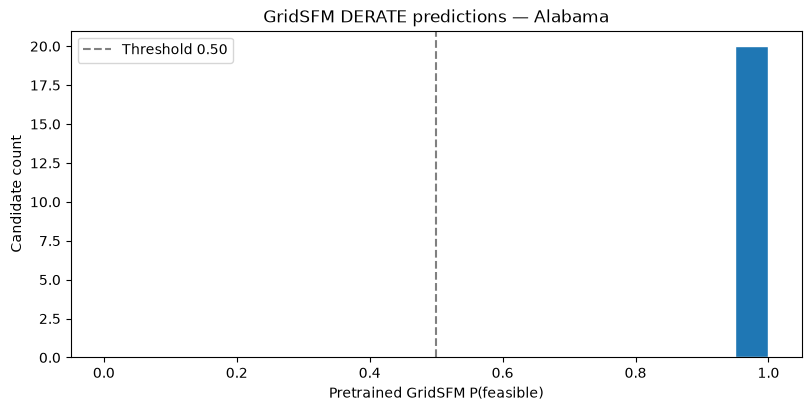

In [5]:
fig,ax=plt.subplots(figsize=(8,4),constrained_layout=True)
ax.hist(model_probs,bins=np.linspace(0,1,21),edgecolor="white")
ax.axvline(MODEL_THRESHOLD,color="gray",linestyle="--",label=f"Threshold {MODEL_THRESHOLD:.2f}")
ax.set(xlabel="Pretrained GridSFM P(feasible)",ylabel="Candidate count",
       title=f"GridSFM DERATE predictions — {DATASET_LABEL}")
ax.legend();fig.savefig(EXPLAIN_ROOT/"model_feasibility_histogram.png",dpi=180,bbox_inches="tight")
plt.show()

## 5. Select a candidate by GridSFM prediction

A dropdown is available when `ipywidgets` is installed. Otherwise set `MANUAL_SCENARIO_INDEX` below. No Julia outcome is used in the dropdown.

In [6]:
FILTERS=["All candidates","Predicted feasible","Predicted infeasible",
         "High confidence feasible (P>=0.9)","High confidence infeasible (P<=0.1)",
         "Near threshold (0.4<=P<=0.6)","Strongest derating (top 10)"]
def matches_filter(row,label):
    p=row["gridsfm_p_feasible"]
    if label=="All candidates": return True
    if label=="Predicted feasible": return p>=MODEL_THRESHOLD
    if label=="Predicted infeasible": return p<MODEL_THRESHOLD
    if label=="High confidence feasible (P>=0.9)": return p>=.9
    if label=="High confidence infeasible (P<=0.1)": return p<=.1
    if label=="Near threshold (0.4<=P<=0.6)": return .4<=p<=.6
    if label=="Strongest derating (top 10)":
        top=sorted(model_rows,key=lambda r:r["mean_derate_factor"])[:10]
        return row["candidate_index"] in {r["candidate_index"] for r in top}
    raise ValueError(label)
def describe_candidate(row):
    return (f"#{row['candidate_index']:03d} | iter {row['iteration']}, sample {row['scenario']} "
            f"| {row['model_category']} | P(feasible)={row['gridsfm_p_feasible']:.4f} "
            f"| avg factor={row['mean_derate_factor']:.3f}")
def show_candidates(filter_name="All candidates",top=40):
    matches=[r for r in model_rows if matches_filter(r,filter_name)]
    print(filter_name,":",len(matches),"candidate(s)")
    for r in matches[:top]: print(" ",describe_candidate(r))
    return matches
try:
    import ipywidgets as widgets
    from IPython.display import display
    WIDGETS_AVAILABLE=True
except ImportError:
    WIDGETS_AVAILABLE=False
if WIDGETS_AVAILABLE:
    FILTER_WIDGET=widgets.Dropdown(options=FILTERS,value="All candidates",description="Filter:",
                                   layout=widgets.Layout(width="96%"))
    CANDIDATE_WIDGET=widgets.Dropdown(description="Candidate:",layout=widgets.Layout(width="96%"))
    def update_dropdown(change=None):
        matches=[r for r in model_rows if matches_filter(r,FILTER_WIDGET.value)]
        wanted=CANDIDATE_WIDGET.value
        CANDIDATE_WIDGET.options=([(describe_candidate(r),r["candidate_index"]) for r in matches]
                                  if matches else [("No matches — change filter",None)])
        if wanted in {r["candidate_index"] for r in matches}: CANDIDATE_WIDGET.value=wanted
    FILTER_WIDGET.observe(update_dropdown,names="value")
    update_dropdown()
    display(widgets.VBox([FILTER_WIDGET,CANDIDATE_WIDGET]))
else:
    print("ipywidgets unavailable; manually set MANUAL_SCENARIO_INDEX below")
show_candidates(top=25)

ipywidgets unavailable; manually set MANUAL_SCENARIO_INDEX below
All candidates : 20 candidate(s)
  #000 | iter 1, sample 1 | Predicted feasible | P(feasible)=0.9998 | avg factor=0.820
  #001 | iter 1, sample 2 | Predicted feasible | P(feasible)=0.9997 | avg factor=0.821
  #002 | iter 2, sample 1 | Predicted feasible | P(feasible)=0.9999 | avg factor=0.828
  #003 | iter 2, sample 2 | Predicted feasible | P(feasible)=0.9998 | avg factor=0.815
  #004 | iter 3, sample 1 | Predicted feasible | P(feasible)=0.9998 | avg factor=0.826
  #005 | iter 3, sample 2 | Predicted feasible | P(feasible)=0.9999 | avg factor=0.827
  #006 | iter 4, sample 1 | Predicted feasible | P(feasible)=0.9998 | avg factor=0.834
  #007 | iter 4, sample 2 | Predicted feasible | P(feasible)=0.9999 | avg factor=0.822
  #008 | iter 5, sample 1 | Predicted feasible | P(feasible)=0.9999 | avg factor=0.818
  #009 | iter 5, sample 2 | Predicted feasible | P(feasible)=0.9999 | avg factor=0.826
  #010 | iter 6, sample 1 | Pred

[{'candidate_index': 0,
  'iteration': 1,
  'scenario': 1,
  'gridsfm_p_feasible': 0.9998339414596558,
  'gridsfm_p_infeasible': 0.00016605854034423828,
  'model_category': 'Predicted feasible',
  'n_derated_lines': 213,
  'mean_derate_factor': 0.8204998970031738,
  'mean_rating_reduction_pct': 17.950010299682617},
 {'candidate_index': 1,
  'iteration': 1,
  'scenario': 2,
  'gridsfm_p_feasible': 0.9996945858001709,
  'gridsfm_p_infeasible': 0.00030541419982910156,
  'model_category': 'Predicted feasible',
  'n_derated_lines': 213,
  'mean_derate_factor': 0.8213357925415039,
  'mean_rating_reduction_pct': 17.86642074584961},
 {'candidate_index': 2,
  'iteration': 2,
  'scenario': 1,
  'gridsfm_p_feasible': 0.9999443292617798,
  'gridsfm_p_infeasible': 5.5670738220214844e-05,
  'model_category': 'Predicted feasible',
  'n_derated_lines': 213,
  'mean_derate_factor': 0.8276373147964478,
  'mean_rating_reduction_pct': 17.236268520355225},
 {'candidate_index': 3,
  'iteration': 2,
  'scena

## 6. Activate a candidate and choose the model class to explain

Use `EXPLANATION_TARGET="predicted"` to explain whichever class GridSFM predicted. Positive SHAP increases the probability of that class; negative SHAP lowers it.

In [7]:
MANUAL_SCENARIO_INDEX=0
EXPLANATION_TARGET="predicted"  # "predicted", "feasible", "infeasible"
assert EXPLANATION_TARGET in ("predicted","feasible","infeasible")
if WIDGETS_AVAILABLE:
    if CANDIDATE_WIDGET.value is None: raise ValueError("No candidates match the current filter")
    SCENARIO_INDEX=int(CANDIDATE_WIDGET.value)
else:
    SCENARIO_INDEX=int(MANUAL_SCENARIO_INDEX)
if not 0<=SCENARIO_INDEX<len(candidates): raise IndexError(SCENARIO_INDEX)
chosen_row=model_rows[SCENARIO_INDEX]
chosen=full_pygrid_ratings(SCENARIO_INDEX)
delta=chosen-original
p_selected=model_probability_pygrid(chosen)
TARGET_CLASS=("feasible" if p_selected>=MODEL_THRESHOLD else "infeasible") if EXPLANATION_TARGET=="predicted" else EXPLANATION_TARGET
p_selected_target=p_selected if TARGET_CLASS=="feasible" else 1-p_selected
p_original_target=p_original if TARGET_CLASS=="feasible" else 1-p_original
selected_ids=[str(b) for b in selected_branch_ids[SCENARIO_INDEX]]
selected_rows=np.asarray([pyg_line_row[b] for b in selected_ids],dtype=int)
EXPLAIN_DIR=EXPLAIN_ROOT/f"candidate_{SCENARIO_INDEX:05d}"
EXPLAIN_DIR.mkdir(parents=True,exist_ok=True)
print("Selected:",describe_candidate(chosen_row))
print(f"Explaining model P({TARGET_CLASS})")
print(f"Original P({TARGET_CLASS})={p_original_target:.6f}; candidate={p_selected_target:.6f}")
print("Derated branch IDs:",selected_ids)

Selected: #000 | iter 1, sample 1 | Predicted feasible | P(feasible)=0.9998 | avg factor=0.820
Explaining model P(feasible)
Original P(feasible)=0.999941; candidate=0.999834
Derated branch IDs: ['407', '86', '410', '492', '296', '128', '316', '347', '434', '497', '188', '220', '381', '238', '114', '430', '647', '173', '425', '152', '383', '508', '144', '539', '376', '211', '576', '104', '267', '490', '62', '462', '122', '443', '453', '37', '223', '321', '470', '450', '396', '313', '398', '348', '245', '510', '531', '280', '233', '143', '88', '45', '12', '212', '638', '25', '201', '408', '131', '431', '130', '107', '646', '259', '132', '33', '177', '632', '465', '92', '156', '286', '121', '452', '602', '164', '343', '99', '310', '163', '232', '274', '93', '292', '538', '606', '30', '307', '444', '618', '242', '304', '290', '411', '550', '54', '526', '176', '180', '102', '644', '273', '484', '324', '305', '151', '149', '614', '192', '209', '219', '365', '194', '40', '253', '337', '226', 

## 7. Visualize the changed line ratings and model verdict

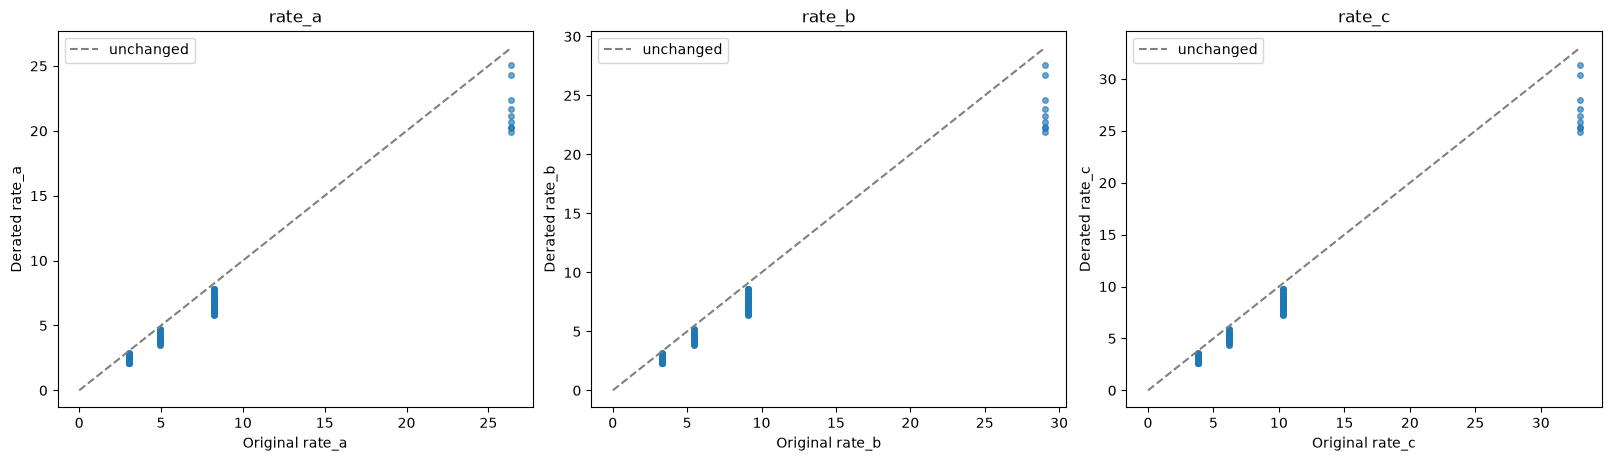

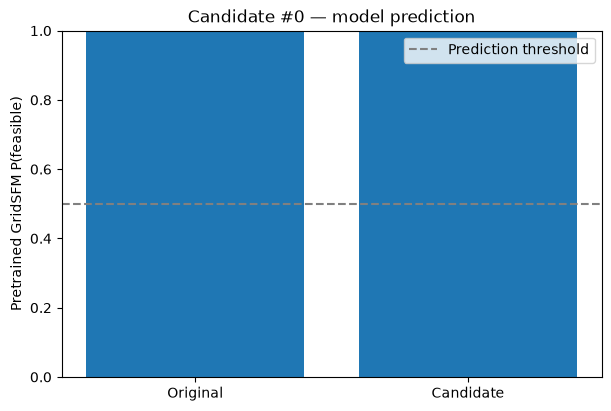

In [8]:
fig,axes=plt.subplots(1,3,figsize=(16,4.5),constrained_layout=True)
for j,label in enumerate(("rate_a","rate_b","rate_c")):
    x=original[selected_rows,j]
    y=chosen[selected_rows,j]
    axes[j].scatter(x,y,s=16,alpha=.65)
    axes[j].plot([0,float(x.max())],[0,float(x.max())],linestyle="--",color="gray",label="unchanged")
    axes[j].set(xlabel=f"Original {label}",ylabel=f"Derated {label}",title=label)
    axes[j].legend()
fig.savefig(EXPLAIN_DIR/"00_original_vs_derated_ratings.png",dpi=180,bbox_inches="tight")
plt.show()

fig,ax=plt.subplots(figsize=(6,4),constrained_layout=True)
ax.bar(["Original","Candidate"],[p_original,p_selected])
ax.axhline(MODEL_THRESHOLD,ls="--",color="gray",label="Prediction threshold")
ax.set(ylim=(0,1),ylabel="Pretrained GridSFM P(feasible)",
       title=f"Candidate #{SCENARIO_INDEX} — model prediction")
ax.legend()
fig.savefig(EXPLAIN_DIR/"01_pretrained_probability.png",dpi=180,bbox_inches="tight")
plt.show()

## 8. Group Kernel SHAP over **all selected derated lines**

A group is a subset of changed **branch IDs**. Each SHAP feature switches all `rate_a/b/c` values for those lines together. The baseline is the **completely original grid**. Groups are sorted by branch ID, not geographic location.

In [9]:
N_GROUPS=min(12,len(selected_rows))
N_GROUP_SHAP_SAMPLES=128  # Increase to 512/1024 for stability
ordered=np.asarray(sorted(range(len(selected_ids)),
    key=lambda i: (0,int(selected_ids[i])) if str(selected_ids[i]).lstrip("-").isdigit()
                  else (1,str(selected_ids[i]))),dtype=int)
ordered_rows=selected_rows[ordered]
line_group=np.empty(len(selected_rows),dtype=int)
line_group[ordered]=(np.arange(len(selected_rows))*N_GROUPS)//len(selected_rows)
assert len(set(line_group))==N_GROUPS

class GroupedRateModel(torch.nn.Module):
    def forward(self,batch_mask):
        mask=batch_mask.detach().cpu().numpy()
        results=[]
        for activations in mask:
            full=original.copy()
            for g in range(N_GROUPS):
                rows=selected_rows[line_group==g]
                full[rows]=original[rows]+activations[g]*(chosen[rows]-original[rows])
            p=model_probability_pygrid(full)
            results.append(p if TARGET_CLASS=="feasible" else 1-p)
        return torch.tensor(results,dtype=torch.float32,device=batch_mask.device)

shap_group_t=KernelShap(GroupedRateModel().eval()).attribute(
    torch.ones((1,N_GROUPS),dtype=torch.float32),
    baselines=torch.zeros((1,N_GROUPS),dtype=torch.float32),
    n_samples=N_GROUP_SHAP_SAMPLES,perturbations_per_eval=1,show_progress=True)
shap_group=shap_group_t.squeeze(0).detach().cpu().numpy()
assert shap_group.shape==(N_GROUPS,) and np.isfinite(shap_group).all()
print("Model target probability difference:",p_selected_target-p_original_target)
print("Group SHAP sum (approximate):",shap_group.sum())
group_rows=[]
for g in range(N_GROUPS):
    ids=[selected_ids[i] for i in range(len(selected_ids)) if line_group[i]==g]
    group_rows.append(dict(group=g+1,branch_ids=",".join(ids),n_lines=len(ids),
                           shap=float(shap_group[g]),
                           mean_rate_a_reduction_pct=float(100*np.mean(1-chosen[selected_rows[line_group==g],0]/
                                                                     original[selected_rows[line_group==g],0]))))

Kernel Shap attribution: 100%|██████████| 128/128 [00:39<00:00,  3.28it/s]


Model target probability difference: -0.00010752677917480469
Group SHAP sum (approximate): -0.0001075267


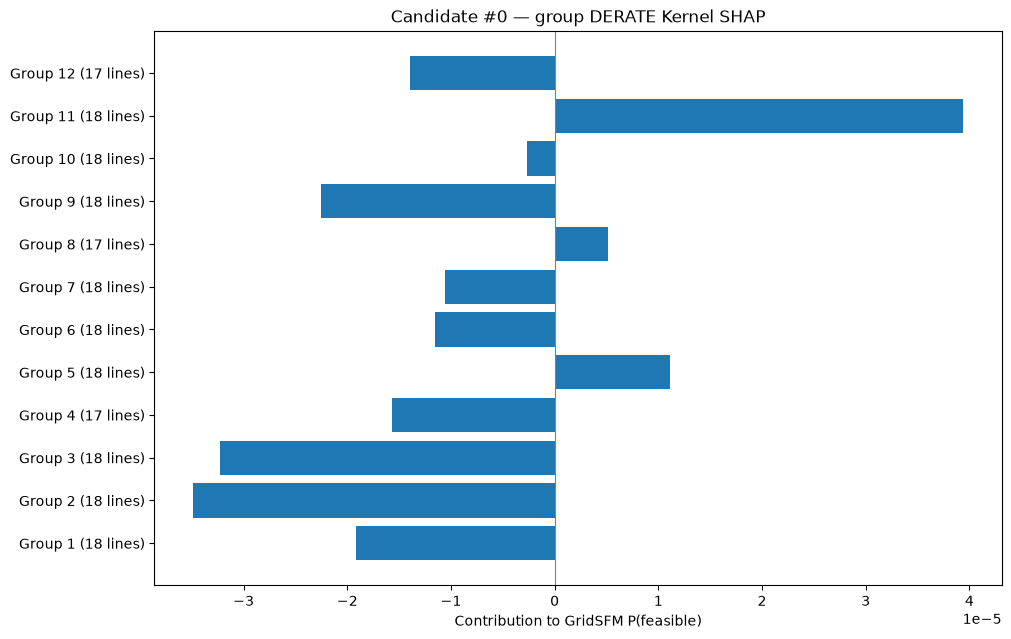

Top groups:
{'group': 11, 'branch_ids': '508,539,576,510,531,538,550,526,498,516,573,590,536,579,502,505,515,585', 'n_lines': 18, 'shap': 3.939734597224742e-05, 'mean_rate_a_reduction_pct': 20.78535270690918}
{'group': 2, 'branch_ids': '86,104,62,88,92,99,93,54,102,87,84,66,79,65,81,50,63,61', 'n_lines': 18, 'shap': -3.488478614599444e-05, 'mean_rate_a_reduction_pct': 19.766944885253906}
{'group': 3, 'branch_ids': '128,114,152,144,122,143,131,130,107,132,156,121,151,149,109,161,142,129', 'n_lines': 18, 'shap': -3.228280183975585e-05, 'mean_rate_a_reduction_pct': 16.20841407775879}
{'group': 9, 'branch_ids': '407,410,434,430,425,443,408,431,444,411,417,447,403,418,401,448,426,427', 'n_lines': 18, 'shap': -2.2532585717272013e-05, 'mean_rate_a_reduction_pct': 18.24952507019043}
{'group': 1, 'branch_ids': '37,45,12,25,33,30,40,13,32,14,31,49,18,4,47,46,36,21', 'n_lines': 18, 'shap': -1.9125127437291667e-05, 'mean_rate_a_reduction_pct': 18.10086441040039}
{'group': 4, 'branch_ids': '188,173

In [10]:
fig,ax=plt.subplots(figsize=(10,max(4,N_GROUPS*.44+1)),constrained_layout=True)
ys=np.arange(N_GROUPS)
ax.barh(ys,shap_group)
ax.set_yticks(ys,[f"Group {g+1} ({group_rows[g]['n_lines']} lines)" for g in ys])
ax.axvline(0,color="gray",lw=.8)
ax.set_xlabel(f"Contribution to GridSFM P({TARGET_CLASS})")
ax.set_title(f"Candidate #{SCENARIO_INDEX} — group DERATE Kernel SHAP")
fig.savefig(EXPLAIN_DIR/"02_group_derate_shap.png",dpi=180,bbox_inches="tight")
plt.show()
print("Top groups:")
for r in sorted(group_rows,key=lambda r:abs(r["shap"]),reverse=True)[:6]:print(r)

## 9. Focused line-level Kernel SHAP: which branches contribute most?

Choose up to 8 individual changed branches from influential groups, or specify `MANUAL_BRANCH_IDS`. Unlike group SHAP, this is **conditional SHAP**: all other candidate lines stay derated, and only the focus lines toggle between original and derated. Therefore the attributions need not sum to the whole-grid prediction difference.

In [11]:
LINE_SHAP_TOP_GROUPS=2
LINE_SHAP_MAX_LINES=8
N_LINE_SHAP_SAMPLES=256
MANUAL_BRANCH_IDS=None  # e.g. ["12","84"] — must have been derated in the selected candidate
if MANUAL_BRANCH_IDS is not None:
    focus_ids=list(dict.fromkeys(str(b) for b in MANUAL_BRANCH_IDS))
    unknown=[b for b in focus_ids if b not in selected_ids]
    if unknown: raise ValueError(f"Not selected for derating in this candidate: {unknown}")
    focus_rows=np.asarray([pyg_line_row[b] for b in focus_ids],dtype=int)
else:
    top_groups=set(np.argsort(np.abs(shap_group))[::-1][:LINE_SHAP_TOP_GROUPS])
    shortlist=np.asarray([selected_rows[i] for i in range(len(selected_rows))
                          if line_group[i] in top_groups],dtype=int)
    if len(shortlist)==0: shortlist=selected_rows.copy()
    strength=np.mean(1-chosen[shortlist]/original[shortlist],axis=1)
    focus_rows=shortlist[np.argsort(strength)[::-1][:LINE_SHAP_MAX_LINES]]
    focus_ids=[pyg_line_ids[int(r)] for r in focus_rows]
assert len(focus_rows)>0

class FocusedLineRateModel(torch.nn.Module):
    def forward(self,batch_mask):
        rows=batch_mask.detach().cpu().numpy()
        predictions=[]
        for mask in rows:
            full=chosen.copy()
            for k,r in enumerate(focus_rows):
                full[r]=original[r]+mask[k]*(chosen[r]-original[r])
            p=model_probability_pygrid(full)
            predictions.append(p if TARGET_CLASS=="feasible" else 1-p)
        return torch.tensor(predictions,dtype=torch.float32,device=batch_mask.device)

shap_line_t=KernelShap(FocusedLineRateModel().eval()).attribute(
    torch.ones((1,len(focus_rows)),dtype=torch.float32),
    baselines=torch.zeros((1,len(focus_rows)),dtype=torch.float32),
    n_samples=N_LINE_SHAP_SAMPLES,perturbations_per_eval=1,show_progress=True)
shap_line=shap_line_t.squeeze(0).detach().cpu().numpy()
assert shap_line.shape==(len(focus_rows),) and np.isfinite(shap_line).all()
conditional_original=chosen.copy()
conditional_original[focus_rows]=original[focus_rows]
p_conditional=model_probability_pygrid(conditional_original)
p_conditional_target=p_conditional if TARGET_CLASS=="feasible" else 1-p_conditional
print("Explained branch IDs:",focus_ids)
print("Conditional probability difference:",p_selected_target-p_conditional_target)
print("Line-level SHAP sum (approximate):",shap_line.sum())

Kernel Shap attribution: 100%|██████████| 256/256 [01:15<00:00,  3.38it/s]


Explained branch IDs: ['79', '54', '585', '550', '86', '65', '502', '81']
Conditional probability difference: 5.602836608886719e-06
Line-level SHAP sum (approximate): 5.6028434e-06


Most influential selected lines (model SHAP, not physical proof):
{'branch_id': '86', 'from_bus': '139', 'to_bus': '140', 'from_bus_name': 'Albertville Substation', 'to_bus_name': 'Alabama Power Substation', 'original_rate_a': 3.0250000953674316, 'derated_rate_a': 2.1882619857788086, 'original_rate_b': 3.327500104904175, 'derated_rate_b': 2.407088279724121, 'original_rate_c': 3.78125, 'derated_rate_c': 2.7353274822235107, 'factor': 0.7233923673629761, 'rating_reduction_pct': 27.660762786865234, 'shap': 3.0354053706105333e-06, 'abs_shap': 3.0354053706105333e-06}
{'branch_id': '502', 'from_bus': '479', 'to_bus': '483', 'from_bus_name': 'BUS_479', 'to_bus_name': 'Linde Gas & Equipment, Inc. Substation', 'original_rate_a': 3.0250000953674316, 'derated_rate_a': 2.2516286373138428, 'original_rate_b': 3.327500104904175, 'derated_rate_b': 2.4767916202545166, 'original_rate_c': 3.78125, 'derated_rate_c': 2.8145358562469482, 'factor': 0.7443400025367737, 'rating_reduction_pct': 25.56599998474121

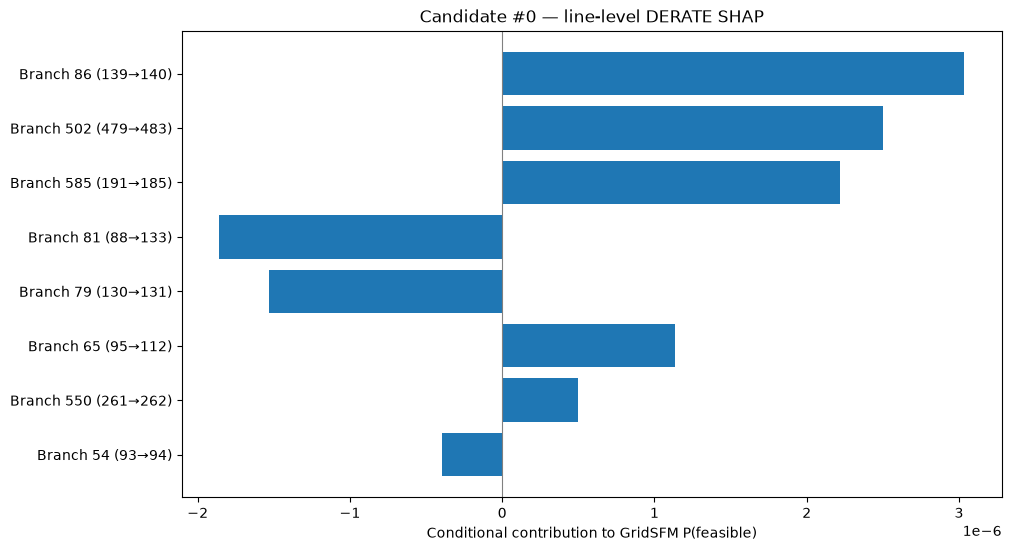

In [12]:
line_rows=[]
for j,bid in enumerate(focus_ids):
    r=int(focus_rows[j])
    b=data["branch"].get(str(bid),{})
    fbus=str(b.get("f_bus",""));tbus=str(b.get("t_bus",""))
    line_rows.append(dict(branch_id=str(bid),from_bus=fbus,to_bus=tbus,
        from_bus_name=str(data["bus"].get(fbus,{}).get("name","")),
        to_bus_name=str(data["bus"].get(tbus,{}).get("name","")),
        original_rate_a=float(original[r,0]),derated_rate_a=float(chosen[r,0]),
        original_rate_b=float(original[r,1]),derated_rate_b=float(chosen[r,1]),
        original_rate_c=float(original[r,2]),derated_rate_c=float(chosen[r,2]),
        factor=float(chosen[r,0]/original[r,0]),
        rating_reduction_pct=float(100*(1-chosen[r,0]/original[r,0])),
        shap=float(shap_line[j]),abs_shap=float(abs(shap_line[j]))))
line_rows.sort(key=lambda x:x["abs_shap"],reverse=True)
print("Most influential selected lines (model SHAP, not physical proof):")
for r in line_rows:print(r)
fig,ax=plt.subplots(figsize=(10,max(4,.55*len(line_rows)+1)),constrained_layout=True)
ys=np.arange(len(line_rows))
ax.barh(ys,[r["shap"] for r in line_rows])
ax.set_yticks(ys,[f"Branch {r['branch_id']} ({r['from_bus']}→{r['to_bus']})" for r in line_rows])
ax.invert_yaxis();ax.axvline(0,color="gray",lw=.8)
ax.set_xlabel(f"Conditional contribution to GridSFM P({TARGET_CLASS})")
ax.set_title(f"Candidate #{SCENARIO_INDEX} — line-level DERATE SHAP")
fig.savefig(EXPLAIN_DIR/"03_line_derate_shap.png",dpi=180,bbox_inches="tight")
plt.show()

## 10. Export model-only predictions, group SHAP, and line SHAP

In [13]:
def write_csv(path,rows):
    if not rows: return
    with Path(path).open("w",newline="",encoding="utf-8") as f:
        w=csv.DictWriter(f,fieldnames=list(rows[0]));w.writeheader();w.writerows(rows)
write_csv(EXPLAIN_DIR/"group_derate_shap.csv",group_rows)
write_csv(EXPLAIN_DIR/"line_derate_shap.csv",line_rows)
info=dict(dataset=DATASET_NAME,candidate_index=int(SCENARIO_INDEX),
          iteration=int(chosen_row["iteration"]),scenario=int(chosen_row["scenario"]),
          gridsfm_p_feasible=float(p_selected),gridsfm_verdict=chosen_row["model_category"],
          explanation_target=TARGET_CLASS,original_target_probability=float(p_original_target),
          selected_target_probability=float(p_selected_target),
          group_shap_baseline="fully_original_network",
          line_shap_baseline="other_derated_lines_remain_modified",
          selected_branch_ids=selected_ids,explained_branch_ids=focus_ids,
          checkpoint=str(CHECKPOINT_PATH),pyg_graph=str(PYG_PATH),
          source_case_sha256=CASE_SHA256)
with (EXPLAIN_DIR/"explanation_summary.json").open("w",encoding="utf-8") as f:
    json.dump(info,f,indent=2)
print("All candidate model scores:",EXPLAIN_ROOT/"pretrained_model_predictions.csv")
print("Selected candidate SHAP:",EXPLAIN_DIR)

All candidate model scores: /Users/punrong_rany/Desktop/Projects/GridSFM/results/gaussian_line_derate/alabama/gridsfm_pretrained_derate_line_shap/pretrained_model_predictions.csv
Selected candidate SHAP: /Users/punrong_rany/Desktop/Projects/GridSFM/results/gaussian_line_derate/alabama/gridsfm_pretrained_derate_line_shap/candidate_00000


## Interpretation, caveats and source notes

- A **positive** SHAP value raises GridSFM's *selected target class* probability, a **negative** value lowers it. If `EXPLANATION_TARGET="predicted"`, the target flips between feasible and infeasible according to the pretrained model's prediction.
- **Group SHAP:** baseline = completely original network; toggles rate_a/b/c for a group of chosen lines together.
- **Line SHAP:** conditional baseline = *all other selected lines remain derated*; only focused lines are toggled. Line-level attributions do not necessarily add up to whole-grid probability difference.
- The line ranking covers **focused derated lines**, not all grid branches. Set `MANUAL_BRANCH_IDS` to inspect specific lines.
- The model may be miscalibrated or out of distribution. A solver non-acceptance during sampling is not necessarily mathematical infeasibility, and Julia **does not determine any prediction or SHAP target here**.
- `rate_a` is the principal thermal limit in standard PowerModels AC-OPF; GridSFM's original `ac_line` features also include `rate_b/c` in columns 7/8. The line-level SHAP score attributes their **joint change** in a physical derating event, not three separately identifiable channel effects.
- Increase `N_GROUP_SHAP_SAMPLES` and `N_LINE_SHAP_SAMPLES` and repeat a candidate for more stable Kernel SHAP estimates.
- GridSFM reference schema: [Microsoft GridSFM model README](https://github.com/microsoft/GridSFM/blob/main/model/README.md) and [topology pipeline](https://github.com/microsoft/GridSFM/blob/main/power_grid/US/topology_solver_pipeline/PIPELINE_DETAILS.md).